# **EDA NFL 2009-2017**
Neste dataset, temos informações sobre os jogos da NFL entre 2009 e 2017. O objetivo desta análise, é explorar os dados, identificar os padrões, tendências e insights que possam ser extraídos. Implementaremos todas as etapas da arquitetura medalhão, onde cada camada representa um nível de processamento e transformação dos dados, permitindo uma análise mais profunda e estruturada.
O intuito é extrair quais times tiveram melhor desempenho, quais jogadores se destacaram, quais estratégias foram mais eficazes e como os resultados variaram ao longo dos anos.

## Objetivo da análise
O objetivo desta análise é explorar os dados da NFL entre 2009 e 2017, identificando padrões, tendências e insights que possam ser extraídos. Em pról de fornecer informações sobre o desempenho dos times, jogadores e estratégias utilizadas no esporte dentro da NFL.

### O que foi utilizado neste notebook?
O notebook atual é composto por análises realizadas em dois outros notebooks aplicados em sala de aula (`Pre_processamento_dados_2`) e (`Pre_processamento_dados_gabarito`) na versão atual, foi utilizada a biblioteca `kagglehub`, onde extraimos as bases.


In [1]:
#pip install pyarrow

### Bibliotecas Utilizadas

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pyarrow
from pathlib import Path

c:\Users\patri\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Importando as bases
- Baixando direto do kaggle

In [3]:
raiz = kagglehub.dataset_download("maxhorowitz/nflplaybyplay2009to2016")
print("raiz do dataset:", raiz)

raiz do dataset: C:\Users\patri\.cache\kagglehub\datasets\maxhorowitz\nflplaybyplay2009to2016\versions\6


### Descobrindo o nome dos arquivos baixados do kaggle

In [4]:
for dirpath, dirnames, filenames in os.walk(raiz):
    for f in filenames:
        print(os.path.relpath(os.path.join(dirpath, f), raiz))

NFL Play by Play 2009-2016 (v3).csv
NFL Play by Play 2009-2017 (v4).csv
NFL Play by Play 2009-2018 (v5).csv


In [5]:
csv_path = os.path.join(raiz, "NFL Play by Play 2009-2017 (v4).csv") # criando o caminho completo para o arquivo CSV
df = pd.read_csv(csv_path) # lendo o arquivo em csv e carregando o df no pandas


C:\Users\patri\AppData\Local\Temp\ipykernel_5428\3522760932.py:2: DtypeWarning: Columns (25: DefTwoPoint, 51: BlockingPlayer) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path) # lendo o arquivo em csv e carregando o df no pandas


## Diagnóstico inicial
Visualizar o tipo dos daods, o nome das colunas, verifcando ausentes e duplicados, os primeiros e últimos registros. Anaálise inicial é importante para entender a estrutura do dataset e identificar possíveis problemas que possam afetar a própria análise, entender como reduzir o tamanho da consulta geral, e como otimizar a análise.

In [6]:
print(df.shape) #total de linhas e colunas do dataset

(407688, 102)


In [7]:
df.head(5) #visualizar os primeiros 5 registros do dataset

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,...,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2009-09-10,2009091000,1,1,NaN,15:00,15,3600.0,0.0,TEN,...,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009
1,2009-09-10,2009091000,1,1,1.0,14:53,15,3593.0,7.0,PIT,...,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009
2,2009-09-10,2009091000,1,1,2.0,14:16,15,3556.0,37.0,PIT,...,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009
3,2009-09-10,2009091000,1,1,3.0,13:35,14,3515.0,41.0,PIT,...,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009
4,2009-09-10,2009091000,1,1,4.0,13:27,14,3507.0,8.0,PIT,...,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009


In [8]:
df.tail(5) #visualizar os últimos 5 registros do dataset

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,...,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
407683,2017-12-31,2017123101,29,4,NaN,00:28,1,28.0,4.0,BAL,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,2017
407684,2017-12-31,2017123101,29,4,3.0,00:28,1,28.0,0.0,BAL,...,-0.397515,0.080409,0.919591,0.050478,0.949522,0.080409,-0.029931,-0.021795,-0.008136,2017
407685,2017-12-31,2017123101,29,4,4.0,00:24,1,24.0,4.0,BAL,...,2.457114,0.050478,0.949522,0.030881,0.969119,0.050478,-0.019597,-0.030603,0.011006,2017
407686,2017-12-31,2017123101,30,4,1.0,00:14,1,14.0,10.0,BAL,...,NaN,0.030881,0.969119,0.000000,1.000000,0.969119,0.030881,NaN,NaN,2017
407687,2017-12-31,2017123101,30,4,NaN,00:00,0,0.0,14.0,BAL,...,NaN,0.000000,1.000000,0.000000,1.000000,0.999159,0.000000,NaN,NaN,2017


## Tamanho do dataset:
Foi utilizado df.info(memory_usage='deep') para obter informações sobre o dataset, incluindo tipos de dados e uso de memória. Identificamos os tipos float64 e int64, que são tipos de dados numéricos e object, que são tipos de dados pesados.

In [9]:
df.info(memory_usage='deep') #informações sobre o dataset, incluindo tipos de dados e uso de memória

<class 'pandas.DataFrame'>
RangeIndex: 407688 entries, 0 to 407687
Columns: 102 entries, Date to Season
dtypes: float64(33), int64(31), str(38)
memory usage: 380.5 MB


### Quantificando o tipo dos dados
- Qnt de colunas por tipo de dados

In [10]:
tipo_dados = df.dtypes.astype(str).value_counts().to_frame("qnt")
print(tipo_dados)

         qnt
str       38
float64   33
int64     31


### Exibição detalhada do dataset
- Informações de todas as colunas do dataset

In [11]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 407688 entries, 0 to 407687
Data columns (total 102 columns):
 #    Column                       Dtype  
---   ------                       -----  
 0    Date                         str    
 1    GameID                       int64  
 2    Drive                        int64  
 3    qtr                          int64  
 4    down                         float64
 5    time                         str    
 6    TimeUnder                    int64  
 7    TimeSecs                     float64
 8    PlayTimeDiff                 float64
 9    SideofField                  str    
 10   yrdln                        float64
 11   yrdline100                   float64
 12   ydstogo                      int64  
 13   ydsnet                       int64  
 14   GoalToGo                     float64
 15   FirstDown                    float64
 16   posteam                      str    
 17   DefensiveTeam                str    
 18   desc                         str 

### Colunas com valores diversos
- Na análise anterior, as colunas `DefTwoPoint` e `BlockingPlayer` possuem valores diversificados

In [12]:
for i in ["DefTwoPoint", "BlockingPlayer"]:
    if i in df.columns:
        print(f"Coluna '{i}' encontrada no DataFrame.")
        print(df[i].map(lambda x: type(x).__name__).head(15)) # imprime os tipos de dados das primeiras linhas da coluna, filtrando pelo nome do tipo do dado

Coluna 'DefTwoPoint' encontrada no DataFrame.
0     float
1     float
2     float
3     float
4     float
5     float
6     float
7     float
8     float
9     float
10    float
11    float
12    float
13    float
14    float
Name: DefTwoPoint, dtype: str
Coluna 'BlockingPlayer' encontrada no DataFrame.
0     float
1     float
2     float
3     float
4     float
5     float
6     float
7     float
8     float
9     float
10    float
11    float
12    float
13    float
14    float
Name: BlockingPlayer, dtype: str


### Valores faltantes

In [13]:
faltantes = df.isna().sum()
porcentagem_faltantes = (faltantes / len(df)) * 100

tabela_faltantes = pd.DataFrame({"faltantes": faltantes,"%": porcentagem_faltantes})
tabela_faltantes =  tabela_faltantes.sort_values("%",ascending=False)
print(tabela_faltantes)

                   faltantes          %
DefTwoPoint           407664  99.994113
BlockingPlayer        407571  99.971302
TwoPointConv          407083  99.851602
ChalReplayResult      404286  99.165538
RecFumbPlayer         403315  98.927366
...                      ...        ...
HomeTeam                   0   0.000000
Timeout_Indicator          0   0.000000
TwoPoint_Prob              0   0.000000
ExPoint_Prob               0   0.000000
Season                     0   0.000000

[102 rows x 2 columns]


## valores diferentes (-1 e desconhecido)

In [14]:
desconhecidos = {}
for c in df.columns:
    qtd = int(df[c].isin([-1, "UNKNOWN", "unknown"]).sum())
    if qtd:
        desconhecidos[c] = qtd

if desconhecidos:
    display(pd.Series(desconhecidos, name="quantidade").sort_values(ascending=False))

Yards.Gained                   9714
ScoreDiff                      7421
ydsnet                         6650
AirYards                       4200
YardsAfterCatch                 908
HomeTimeouts_Remaining_Post     108
HomeTimeouts_Remaining_Pre       99
AwayTimeouts_Remaining_Post      80
AwayTimeouts_Remaining_Pre       67
Name: quantidade, dtype: int64

In [ ]:
df["DefTwoPoint"] = df["DefTwoPoint"].replace(-1, np.nan) # substituindo valores -1 por NaN na coluna "DefTwoPoint"
df["BlockingPlayer"] = df["BlockingPlayer"].replace("UNKNOWN", np.nan) # substituindo valores "UNKNOWN" por NaN na coluna "BlockingPlayer"

### diminuindo o tamanho do dataset
- Convertendo colunas para tipos de dados mais eficientes, como `category` para colunas com valores repetidos, e `int8` ou `float32` para colunas numéricas, reduzindo o uso de memória.

In [17]:
## mudando colunas int64 para int8 e float64 para float32
for col in df.select_dtypes(include=['int64']).columns:
    df[col] = df[col].astype('int8')

for col in df.select_dtypes(include=['float64']).columns:
    df[col] = df[col].astype('float32')

print(df.info(memory_usage='deep')) #informações sobre o dataset, incluindo tipos de dados e uso de memória
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 407688 entries, 0 to 407687
Columns: 102 entries, Date to Season
dtypes: float32(33), int8(31), str(38)
memory usage: 244.8 MB
None


Date            str
GameID         int8
Drive          int8
qtr            int8
down        float32
             ...   
Win_Prob    float32
WPA         float32
airWPA      float32
yacWPA      float32
Season         int8
Length: 102, dtype: object

### Tratando coluna down
- A coluna down possui valores vazios quando não há down, ou seja, quando não há jogada. Trocaremos os valores vazios por 0, para que possamos analisar a coluna de forma mais eficiente

In [26]:
downs_faltantes = df["down"].isna().sum()
df["down"] = df["down"].fillna(0) # mudando de nan p zero
print("Quantidade de valores faltantes na coluna 'down':", downs_faltantes)
print("Quantidade de valores faltantes na coluna 'down' após tratamento:", df["down"].isna().sum())
print("\nQuantas jogadas em cada down:")
display(df["down"].value_counts().sort_index().to_frame("jogadas"))

Quantidade de valores faltantes na coluna 'down': 0
Quantidade de valores faltantes na coluna 'down' após tratamento: 0

Quantas jogadas em cada down:


,jogadas
down,
0,61154
1,138878
2,104089
3,67398
4,36169


## Salvando em parquet
- Salvando o dataset tratado em um arquivo no formato parquet, um formato menor que outros formatos, como CSV

In [28]:
parquet_df_path= os.path.join(raiz, "nfl_play_by_play.parquet") # criando o caminho completo para o arquivo parquet
df.to_parquet(parquet_df_path, index=False) # salvando o dataset tratado em um arquivo no formato parquet

### Jogadas mais frequentes

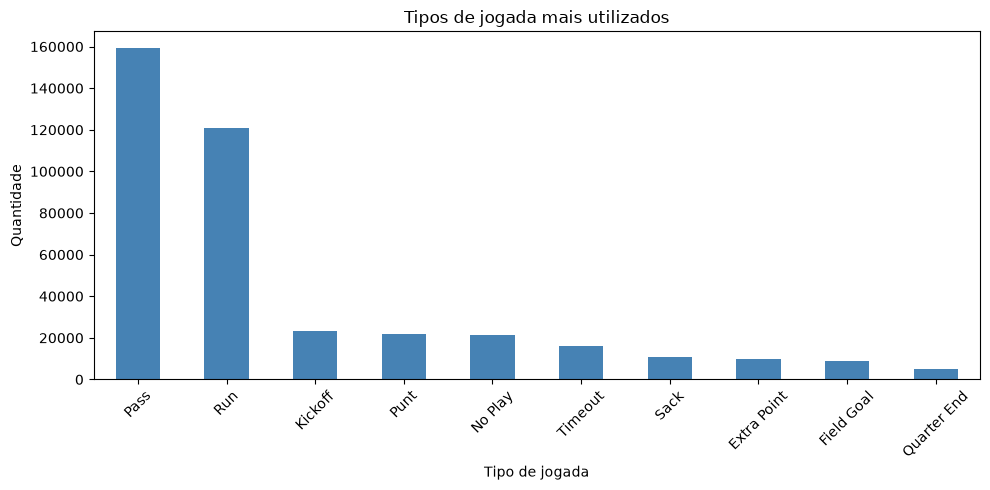

In [42]:
df["PlayType"].value_counts().head(10).plot(
    kind="bar", figsize=(10, 5), color="steelblue"
)

plt.title("Tipos de jogada mais utilizados")
plt.xlabel("Tipo de jogada")
plt.ylabel("Quantidade")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Times com mais touchdowns

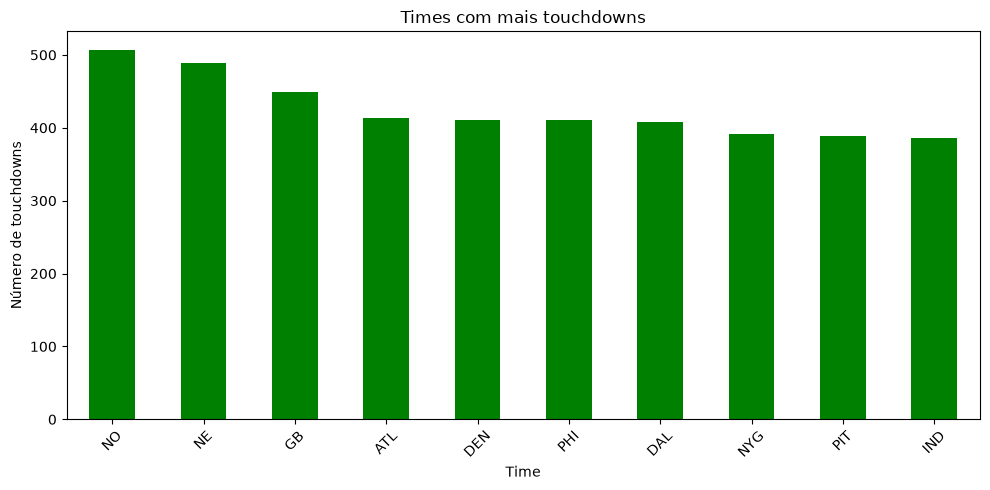

In [43]:
df.loc[df["Touchdown"].eq(1), "posteam"].value_counts().head(10).plot(
    kind="bar", figsize=(10, 5), color="green"
)

plt.title("Times com mais touchdowns")
plt.xlabel("Time")
plt.ylabel("Número de touchdowns")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Média de jardas por tipo de jogada
- Jardas são uma métrica importante para avaliar o desempenho das jogadas. A média de jardas por tipo de jogada pode fornecer insights sobre quais tipos de jogadas são mais eficazes em termos de ganho de terreno

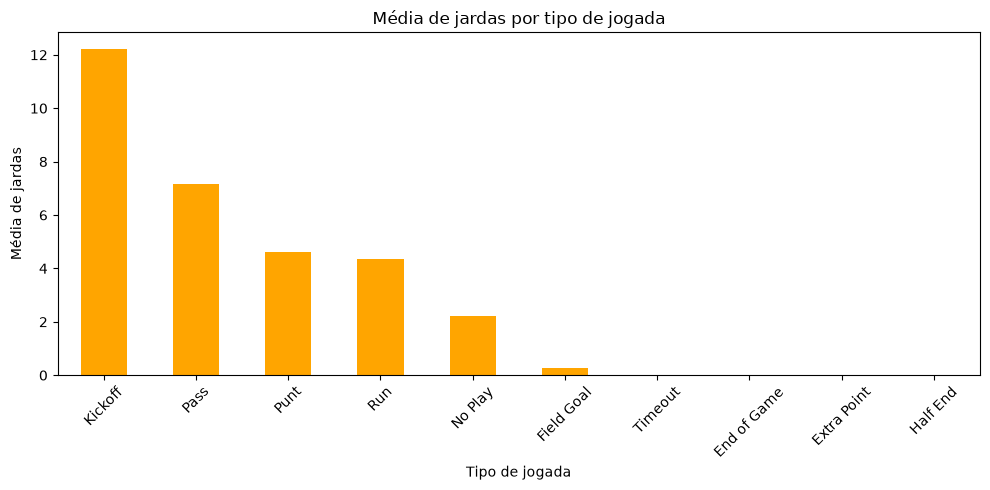

In [44]:
df.groupby("PlayType")["Yards.Gained"].mean().sort_values(
    ascending=False
).head(10).plot(kind="bar", figsize=(10, 5), color="orange")

plt.title("Média de jardas por tipo de jogada")
plt.xlabel("Tipo de jogada")
plt.ylabel("Média de jardas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Conclusão
- A análise exploratória dos dados da NFL entre 2009 e 2017 permitiu identificar padrões, tendências e insights sobre o desempenho dos times, jogadores e estratégias utilizadas no esporte. Através da análise das jogadas mais frequentes, dos times com mais touchdowns e da média de jardas por tipo de jogada, foi possível obter informações valiosas para entender melhor o jogo e suas jogadas. Além disso, a utilização de técnicas de pré-processamento e otimização do dataset permitiu uma análise mais eficiente e precisa dos dados.
- Colunas com vazios: Todas as colunas possuem valores vazios, sendo que algumas possuem uma quantidade significativa de valores ausentes. A coluna `DefTwoPoint` possui 99,9% de valores ausentes, enquanto a coluna `BlockingPlayer` possui 99,8% de valores ausentes. As colunas `Passer`, `Rusher` e `Receiver` possuem 0,1% de valores ausentes, enquanto a coluna `PassResult` possui 0,2% de valores ausentes. As demais colunas possuem menos de 0,1% de valores ausentes.
- Salvar o arquivo no formato parquet, um formato menor que outros formatos, como CSV, permite uma análise mais eficiente e rápida dos dados.

In [45]:
print(raiz)
print(parquet_df_path)

C:\Users\patri\.cache\kagglehub\datasets\maxhorowitz\nflplaybyplay2009to2016\versions\6
C:\Users\patri\.cache\kagglehub\datasets\maxhorowitz\nflplaybyplay2009to2016\versions\6\nfl_play_by_play.parquet
